# Learning SDE solution maps

We consider stochastic differential equations $$dX_t= b(t,X_t)dt+\sigma(t,X_t)dB_t$$
with smooth coefficients $(b,\sigma)$, which can be seen as continuous image of the rough path Brownian noise, i.e. $X_T=f(\mathbf{W}|_{[0,T]})$ for some continuous function $f$.

In this notebook we try to learn the function $f$ using the Signature-Nadaraya-Watson estimator, and we compare the performance for different choices of semi-metrics, signature and not signature related.

In [ ]:
import sys
import os
# Add parent directory to path so we can import from nwsig package
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), '..')))

import iisignature as ii
import numpy as np
import matplotlib.pyplot as plt

# Import from nwsig package
from nwsig import NWSignatureRegressor
from nwsig.metrics import MSE

## Example:


$$dX_t = -X_t^pdt+ \mathrm{cos}(X_t)dW_t, \quad 0 \leq t \leq T$$

In [17]:
#main code for running the experiments
import time as time
def run_sde_experiments(M_values, N=400, T=1, x0=1, truncation_levels=[1,2,3,4,5,6],p_values = [1,2,4,6,8]):
    """
    Run SDE simulation experiments for different sample sizes M
    """
    # Get the maximum M to generate data only once
    max_M = max(M_values)*2
   
    
    # Define all methods (robust signatures with different truncation levels + standard metrics)
    method_configs = []
    
    # Add robust signature methods with different truncation levels
    for k in truncation_levels:
        method_configs.append(('robust_signature', k))
        method_configs.append(('classical_signature', k))
        
    for p in p_values:
        method_configs.append(('p_variation', p))
        
    
    # Add standard metrics (no truncation level dependency)
    method_configs.append(('supremum', None))
    method_configs.append(('l1', None))
    method_configs.append(('l2', None))
    
    # Create method names for results
    method_names = []
    for method, k in method_configs:
        if k is not None:
            method_names.append(f"{method}_K{k}")
        else:
            method_names.append(method)
    
    # Initialize results storage
    num_methods = len(method_configs)
    mse_results = np.zeros((len(M_values), num_methods))
    time_results = np.zeros((len(M_values), num_methods))
    best_bandwidths = {}
    
    # Generate time grid
    tt = np.linspace(0, T, N+1)
    dt = tt[1] - tt[0]
    
    # Generate all data once
    print(f"Generating {max_M} sample paths...")
    X = x0*np.ones((max_M, N+1))
    dW = np.sqrt(dt)*np.random.normal(size=(max_M, N))
    
    # Simulate the SDE
    for i in range(N):
        X[:, i+1] = X[:, i] - X[:,i]**5*dt + np.cos(X[:,i])*X[:,i]*dW[:,i]
    
    W = np.insert(np.cumsum(dW, axis=1), 0, 0, axis=1)
    
    # Create augmented W with time component
    W_augmented = np.zeros((max_M, N+1, 2))
    W_augmented[:, :, 0] = tt
    W_augmented[:, :, 1] = W
    
    # Run experiments for each M value
    for m_idx, M in enumerate(M_values):
        print(f"\nRunning experiment with M = {M}")
        
        # Use subset of data
        X_subset = X[:M]
        W_aug_subset = W_augmented[:M]
        
        # Calculate training/testing split
        M_training = M
        
        # Run for each method configuration
        for method_idx, (method, k) in enumerate(method_configs):
            start_time = time.time()

            if method == 'classical_signature':
                print(f"  Running classical signature method with K={k}")
                NW = NWSignatureRegressor(
                    input_type='paths', 
                    bandwidth_grid=[0.1, 0.05, 0.01, 0.005, 0.001],
                    signature_level=k,
                    robust=False,
                    robust_a_grid=[0.5, 1],
                    robust_C_grid=[2,10,20],
                    initial_condition=False,
                    metric_choice="signature_metric"
                ).fit(W_aug_subset[0:M_training,:,:], W_aug_subset[0:M_training,0,:], X_subset[0:M_training,-1])
                
            
            if method == 'robust_signature':
                print(f"  Running robust signature method with K={k}")
                NW = NWSignatureRegressor(
                    input_type='paths', 
                    bandwidth_grid=[0.1, 0.05, 0.01, 0.005, 0.001],
                    signature_level=k,
                    robust=True,
                    robust_a_grid=[0.5, 1],
                    robust_C_grid=[2,10,20],
                    initial_condition=False,
                    metric_choice="signature_metric"
                ).fit(W_aug_subset[0:M_training,:,:], W_aug_subset[0:M_training,0,:], X_subset[0:M_training,-1])
            if method == 'p_variation':
                print(f"  Running p variation method with K={k}")
                NW = NWSignatureRegressor(
                    input_type='paths', 
                    bandwidth_grid=[2,1, 0.1, 0.01, 0.001,0.0001,0.00001],
                    signature_level=max(truncation_levels),  # Use the highest level for fairness
                    robust=False,
                    initial_condition=False,
                    metric_choice="pvar",
                    p_param = k
                ).fit(W_aug_subset[0:M_training,:,:], W_aug_subset[0:M_training,0,:], X_subset[0:M_training,-1])
                
            elif method == 'supremum':
                print("  Running supremum metric")
                NW = NWSignatureRegressor(
                    input_type='paths', 
                    bandwidth_grid=[10, 1, 0.1, 0.01, 0.001],
                    signature_level=max(truncation_levels),  # Use the highest level for fairness
                    robust=False,
                    initial_condition=False,
                    metric_choice="supremum_metric"
                ).fit(W_aug_subset[0:M_training,:,:], W_aug_subset[0:M_training,0,:], X_subset[0:M_training,-1])
                
            elif method == 'l1':
                print("  Running L1 metric")
                NW = NWSignatureRegressor(
                    input_type='paths', 
                    bandwidth_grid=[10, 1, 0.1, 0.01, 0.001],
                    metric_choice="l1"
                ).fit(W_aug_subset[0:M_training,:,:], W_aug_subset[0:M_training,0,:], X_subset[0:M_training,-1])
                
            elif method == 'l2':
                print("  Running L2 metric")
                NW = NWSignatureRegressor(
                    input_type='paths', 
                    bandwidth_grid=[10, 1, 0.1, 0.01, 0.001],
                    metric_choice="l2"
                ).fit(W_aug_subset[0:M_training,:,:], W_aug_subset[0:M_training,0,:], X_subset[0:M_training,-1])
            
            # Make predictions and calculate MSE
            predictions = NW.predict(W_augmented[M_values[-1]:,:,:], W_augmented[M_values[-1]:,0,:])
            mse_results[m_idx, method_idx] = MSE(predictions, X[M_values[-1]:, -1])
            time_results[m_idx, method_idx] = time.time() - start_time
            
            # Save bandwidth if available
            if hasattr(NW, 'best_bandwidth_'):
                best_bandwidths[f'{method_names[method_idx]}_M{M}'] = NW.best_bandwidth_
            if hasattr(NW, "best_alpha_"):
                best_bandwidths[f"ridge_signature_K{k}_M{M}"] = NW.best_alpha_
            
            print(f"    MSE: {mse_results[m_idx, method_idx]:.6f}, Time: {time_results[m_idx, method_idx]:.2f}s")
        
    return {
        'M_values': M_values,
        'method_names': method_names,
        'mse_results': mse_results,
        'time_results': time_results,
        'best_bandwidths': best_bandwidths
    }

In [24]:
# Define the M values to test
M_values = [2**i for i in range(3,14)]  # You can adjust these values
truncation_levels = [1, 2, 3,4]
p_values = []

#Run the experiments  NOTE: we exclude p-variation here as it is extremly time-consuming!
results = run_sde_experiments(M_values, truncation_levels=truncation_levels,p_values = p_values)


Generating 16384 sample paths...

Running experiment with M = 8
  Running robust signature method with K=1
Fitting NW estimator with input_type='paths'
Input shape: (8, 401, 2), target shape: (8,)
Target statistics: mean=0.529912, std=0.344210, range=[0.070548, 1.110265]
Computing signatures from paths...
Starting cross-validation for bandwidth selection...
CV over robust parameters: 3 C values, 2 a values
Cross-validation: Testing 30 total parameter combinations
  Signature levels: 1
  Bandwidths: 5
  Robust parameters: 6
Testing signature level 1...
Computed signatures shape: (8, 2)
  Testing robust parameters C=2, a=0.5
    New best: level=1, bandwidth=0.1, C=2, a=0.5, score=0.019431
    New best: level=1, bandwidth=0.05, C=2, a=0.5, score=0.017726
    New best: level=1, bandwidth=0.01, C=2, a=0.5, score=0.014061
  Testing robust parameters C=2, a=1
    New best: level=1, bandwidth=0.01, C=2, a=1, score=0.014050
  Testing robust parameters C=10, a=0.5
    New best: level=1, bandwidt

In [25]:

method_configs = []
    
    # Add robust signature methods with different truncation levels
for k in truncation_levels:
        method_configs.append(('robust_signature', k))
        method_configs.append(('classical_signature', k))
for p in p_values:
        method_configs.append(('p_variation', p))
        
    
# Add standard metrics (no truncation level dependency)
method_configs.append(('supremum', None))
method_configs.append(('l1', None))
method_configs.append(('l2', None))
    
    # Create method names for results
method_names = []
for method, k in method_configs:
        if k is not None:
            method_names.append(f"{method}_K{k}")
        else:
            method_names.append(method)


## Comparing performance for different metrics

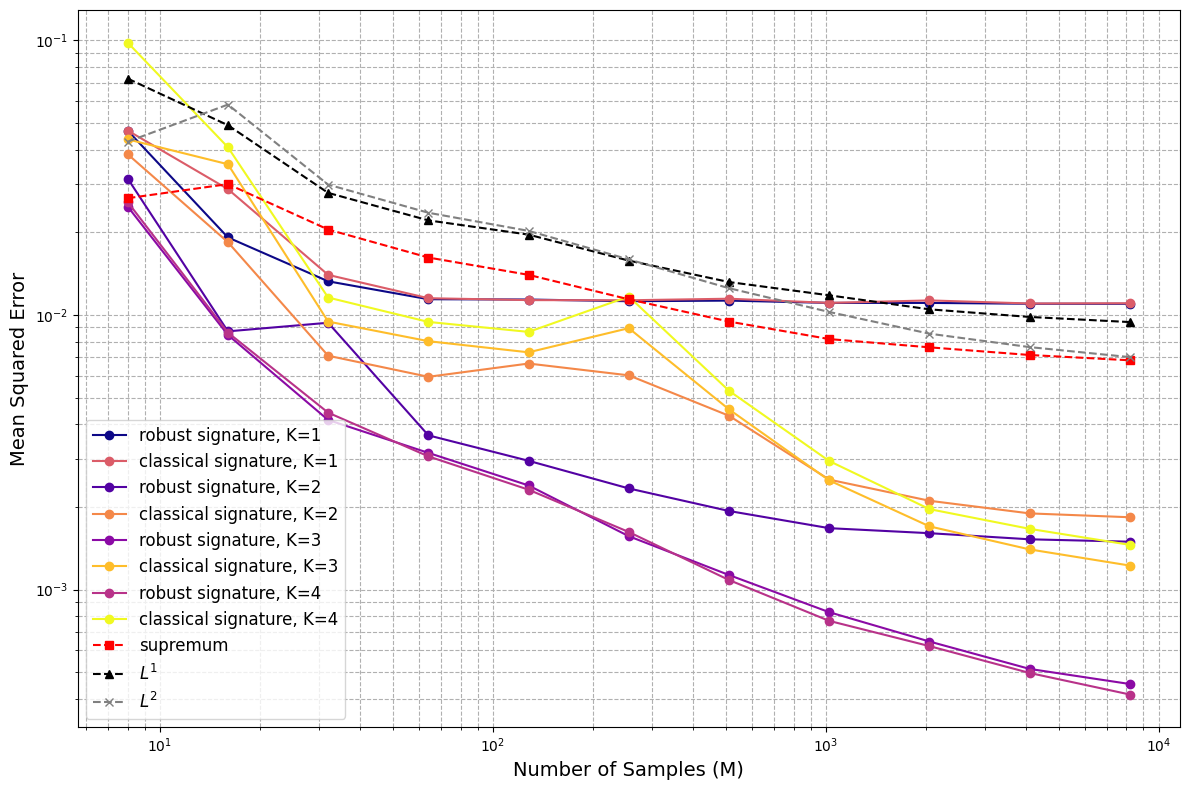

In [26]:
data =results
M_values = data['M_values']
method_names = method_names
mse_results = data['mse_results']
time_results = data['time_results']

results = {
        'M_values': M_values,
        'method_names': method_names,
        'mse_results': mse_results,
        'time_results': time_results
    }



# Create comparison plot with different colors for truncation levels
plt.figure(figsize=(12, 8))
colormap = plt.cm.plasma(np.linspace(0, 1, 2*len(truncation_levels)))
sup_idx = results['method_names'].index('supremum')
l1_idx = results['method_names'].index('l1')
l2_idx = results['method_names'].index('l2')

# Plot robust signature methods with color gradient by truncation level
for i, k in enumerate(truncation_levels):
    method_idx = results['method_names'].index(f'robust_signature_K{k}')
    plt.loglog(results['M_values'], results['mse_results'][:, method_idx], marker='o', 
               color=colormap[i], label=f'robust signature, K={k}')
    method_idx = results['method_names'].index(f'classical_signature_K{k}')
    plt.loglog(results['M_values'], results['mse_results'][:, method_idx], marker='o', 
               color=colormap[i+len(truncation_levels)], label=f'classical signature, K={k}')

# Plot standard metrics
plt.loglog(results['M_values'], results['mse_results'][:, sup_idx], marker='s', 
           linestyle='--', color='red', label='supremum')
plt.loglog(results['M_values'], results['mse_results'][:, l1_idx], marker='^', 
           linestyle='--', color='black', label='$L^1$')
plt.loglog(results['M_values'], results['mse_results'][:, l2_idx], marker='x', 
           linestyle='--', color='gray', label='$L^2$')

p_markers = ['d', '*', 'v','o']  # diamond, star, triangle-down
p_colors = plt.cm.viridis(np.linspace(0, 1, len(p_values)))
for i, p_idx in enumerate(p_values):
    method_idx = results['method_names'].index(f'p_variation_K{p_idx}')
    plt.loglog(results['M_values'], results['mse_results'][:, method_idx], marker=p_markers[i], 
               linestyle='-.', color=p_colors[i], label=f'p-variation, p={p_values[i]}')

    
plt.xlabel('Number of Samples (M)', fontsize=14)
plt.ylabel('Mean Squared Error', fontsize=14)
#plt.title('Comparison of Robust Signature Methods vs Standard Metrics', fontsize=16)
plt.grid(True, which="both", ls="--")
plt.legend(fontsize=12)
plt.tight_layout()
#plt.savefig('robust_signature_vs_standard_metrics.pdf')



## Comparing run-times for different methods:

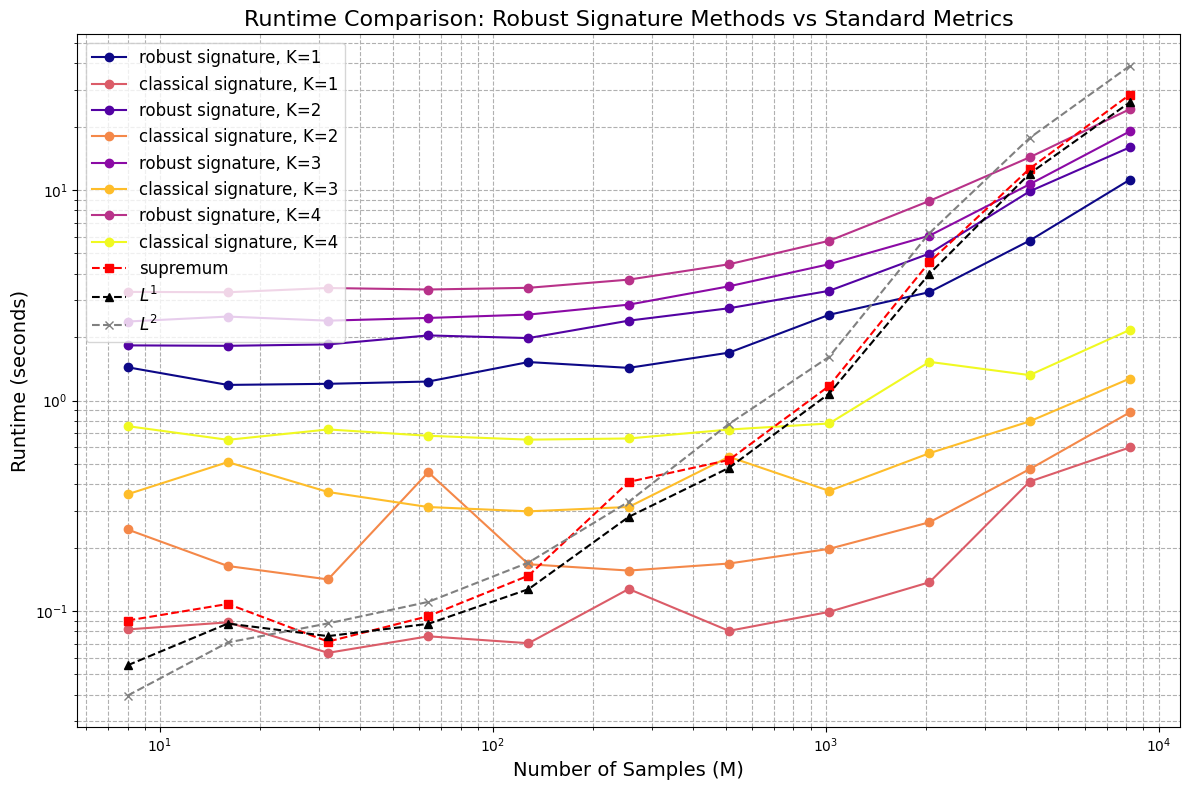

In [27]:
# Create comparison plot for runtimes with different colors for truncation levels
plt.figure(figsize=(12, 8))
colormap = plt.cm.plasma(np.linspace(0, 1, 2*len(truncation_levels)))
sup_idx = results['method_names'].index('supremum')
l1_idx = results['method_names'].index('l1')
l2_idx = results['method_names'].index('l2')

# Plot robust signature methods with color gradient by truncation level
for i, k in enumerate(truncation_levels):
    method_idx = results['method_names'].index(f'robust_signature_K{k}')
    plt.loglog(results['M_values'], results['time_results'][:, method_idx], marker='o', 
               color=colormap[i], label=f'robust signature, K={k}')
    method_idx = results['method_names'].index(f'classical_signature_K{k}')
    plt.loglog(results['M_values'], results['time_results'][:, method_idx], marker='o', 
               color=colormap[i+len(truncation_levels)], label=f'classical signature, K={k}')

# Plot standard metrics
plt.loglog(results['M_values'], results['time_results'][:, sup_idx], marker='s', 
           linestyle='--', color='red', label='supremum')
plt.loglog(results['M_values'], results['time_results'][:, l1_idx], marker='^', 
           linestyle='--', color='black', label='$L^1$')
plt.loglog(results['M_values'], results['time_results'][:, l2_idx], marker='x', 
           linestyle='--', color='gray', label='$L^2$')

# Plot p-variation metrics
p_markers = ['d', '*', 'v','o']  # diamond, star, triangle-down, circle
p_colors = plt.cm.viridis(np.linspace(0, 1, len(p_values)))
for i, p_idx in enumerate(p_values):
    method_idx = results['method_names'].index(f'p_variation_K{p_idx}')
    plt.loglog(results['M_values'], results['time_results'][:, method_idx], marker=p_markers[i], 
               linestyle='-.', color=p_colors[i], label=f'p-variation, p={p_values[i]}')

plt.xlabel('Number of Samples (M)', fontsize=14)
plt.ylabel('Runtime (seconds)', fontsize=14)
plt.title('Runtime Comparison: Robust Signature Methods vs Standard Metrics', fontsize=16)
plt.grid(True, which="both", ls="--")
plt.legend(fontsize=12)
plt.tight_layout()
#plt.savefig('runtime_comparison.pdf')

#print("\nRuntime comparison plot saved!")


## Generating tables as in the paper:

In [28]:
#Create table for the paper:
import numpy as np
import pandas as pd

# Example data (replace with your computed errors!)
M_values = np.array([50, 100, 200, 400])


# Put into a DataFrame
df = pd.DataFrame({
    r"$\mathrm{RSig}^{\leq 2}$": np.sqrt(results['mse_results'][:,results['method_names'].index(f'robust_signature_K{2}')]),
    r"$\mathrm{Sig}^{\leq 2}$": np.sqrt(results['mse_results'][:,results['method_names'].index(f'classical_signature_K{2}')]),
    r"$\mathrm{RSig}^{\leq 3}$": np.sqrt(results['mse_results'][:,results['method_names'].index(f'robust_signature_K{3}')]),
    r"$\mathrm{Sig}^{\leq 3}$": np.sqrt(results['mse_results'][:,results['method_names'].index(f'classical_signature_K{3}')]),
    r"$\mathrm{RSig}^{\leq 4}$": np.sqrt(results['mse_results'][:,results['method_names'].index(f'robust_signature_K{4}')]),
    r"$\mathrm{Sig}^{\leq 4}$": np.sqrt(results['mse_results'][:,results['method_names'].index(f'classical_signature_K{4}')]),
    r"$L^1$": np.sqrt(results['mse_results'][:,l1_idx]),
    r"$L^2$": np.sqrt(results['mse_results'][:,l2_idx]),
    r"$\mathrm{sup}$": np.sqrt(results['mse_results'][:,sup_idx])
}, index=results['M_values'])

# Name the index
df.index.name = r"$M$"


comp_times = np.max(results['time_results'],axis=0)
comp_times = comp_times[2:] #exclude level 1 signatures

# Display table
df.loc["max. run time (s)"] = comp_times
df


,$\mathrm{RSig}^{\leq 2}$,$\mathrm{Sig}^{\leq 2}$,$\mathrm{RSig}^{\leq 3}$,$\mathrm{Sig}^{\leq 3}$,$\mathrm{RSig}^{\leq 4}$,$\mathrm{Sig}^{\leq 4}$,$L^1$,$L^2$,$\mathrm{sup}$
$M$,,,,,,,,,
8,0.177087,0.196115,0.157479,0.208723,0.160469,0.313125,0.269243,0.206717,0.163096
16,0.093334,0.135635,0.091939,0.188065,0.092863,0.201917,0.221476,0.241475,0.173033
32,0.096759,0.084270,0.064375,0.097239,0.066380,0.107545,0.166773,0.172658,0.143026
64,0.060359,0.077145,0.056083,0.089569,0.055270,0.097100,0.148624,0.153446,0.127191
128,0.054247,0.081556,0.048923,0.085482,0.048057,0.093119,0.140004,0.142219,0.118279
256,0.048314,0.077617,0.039547,0.094591,0.040249,0.107999,0.125552,0.126173,0.106749
512,0.043954,0.065519,0.033607,0.067302,0.032909,0.072748,0.114768,0.111837,0.097246
1024,0.040901,0.050127,0.028759,0.049965,0.027731,0.054195,0.108554,0.101232,0.090360
2048,0.040050,0.045880,0.025433,0.041212,0.024947,0.044300,0.102356,0.092427,0.087290


In [30]:
#convert it to latex table
# Convert to LaTeX string

latex_table = df.round(3).to_latex(
    escape=False,
    float_format="%.3f"
)

lines = latex_table.splitlines()

# Find the row that contains "max. run time (s)"
for i, line in enumerate(lines):
    if "max. run time (s)" in line:
        lines.insert(i, r"\midrule")  # insert rule before this row
        break

latex_table = "\n".join(lines)
# Print the LaTeX code in the notebook
print(latex_table)

# Or save directly to file
with open("convergence_table.tex", "w") as f:
    f.write(latex_table)


\begin{tabular}{lrrrrrrrrr}
\toprule
 & $\mathrm{RSig}^{\leq 2}$ & $\mathrm{Sig}^{\leq 2}$ & $\mathrm{RSig}^{\leq 3}$ & $\mathrm{Sig}^{\leq 3}$ & $\mathrm{RSig}^{\leq 4}$ & $\mathrm{Sig}^{\leq 4}$ & $L^1$ & $L^2$ & $\mathrm{sup}$ \\
$M$ &  &  &  &  &  &  &  &  &  \\
\midrule
8 & 0.177 & 0.196 & 0.157 & 0.209 & 0.160 & 0.313 & 0.269 & 0.207 & 0.163 \\
16 & 0.093 & 0.136 & 0.092 & 0.188 & 0.093 & 0.202 & 0.221 & 0.241 & 0.173 \\
32 & 0.097 & 0.084 & 0.064 & 0.097 & 0.066 & 0.108 & 0.167 & 0.173 & 0.143 \\
64 & 0.060 & 0.077 & 0.056 & 0.090 & 0.055 & 0.097 & 0.149 & 0.153 & 0.127 \\
128 & 0.054 & 0.082 & 0.049 & 0.085 & 0.048 & 0.093 & 0.140 & 0.142 & 0.118 \\
256 & 0.048 & 0.078 & 0.040 & 0.095 & 0.040 & 0.108 & 0.126 & 0.126 & 0.107 \\
512 & 0.044 & 0.066 & 0.034 & 0.067 & 0.033 & 0.073 & 0.115 & 0.112 & 0.097 \\
1024 & 0.041 & 0.050 & 0.029 & 0.050 & 0.028 & 0.054 & 0.109 & 0.101 & 0.090 \\
2048 & 0.040 & 0.046 & 0.025 & 0.041 & 0.025 & 0.044 & 0.102 & 0.092 & 0.087 \\
4096 & 0.039 & 0